In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
%cd /content/drive/MyDrive/Colab Notebooks/ICT110(SAMILLANO)

/content/drive/MyDrive/Colab Notebooks/ICT110(SAMILLANO)


##Exercise 2.1

Load to a dataframe the file `GDP(PPP)_LifeExpectancy.xlsx` in the folder `Datasets`.
- Don't load the column Code which contains the full name of the country
- Use the following column names: 'Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class'
- Encode invalid values to `np.nan`

In [5]:

import pandas as pd
import numpy as np


file_name = 'Datasets/GDP(PPP)_LifeExpectancy.xlsx'
data = pd.read_excel(
    file_name,
    na_values=['...', '..', 'N/A', 'NA', '']
)


df_gdp = data.pivot_table(
    values='2022 [YR2022]',
    index='Country Name',
    columns='Series Name'
).reset_index()


df_gdp.columns = [
    'Country' if col == 'Country Name' else
    'GDP' if col == 'GDP per capita, PPP (current international $)' else
    'Life_Exp' if col == 'Life expectancy at birth, total (years)' else col
    for col in df_gdp.columns
]


df_gdp = df_gdp.assign(
    Population=np.nan,
    Inc_Class=np.nan
)


df_gdp = df_gdp.reindex(columns=[
    'Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class'
])


df_gdp.head()


,Country,Life_Exp,GDP,Population,Inc_Class
0,Afghanistan,65.617,2122.995815,NaN,NaN
1,Albania,78.769,19444.706898,NaN,NaN
2,Algeria,76.129,15836.094437,NaN,NaN
3,American Samoa,72.752,NaN,NaN,NaN
4,Andorra,84.016,68470.075948,NaN,NaN


## Exercise 3.1

The BitCoin Year-on-Year price data in CSV format could be found in this link: https://api.blockchain.info/charts/market-price?format=csv.
1. Download a copy of the CSV file and observe its characteristics.
2. Load the file directly from the url/website and assign it to a DataFrame called `df_bitcoin`
3. Plot the data

,Price
Date,
2025-10-27,114531.59
2025-10-28,114121.46
2025-10-29,112923.91
2025-10-30,110068.52
2025-10-31,108303.21


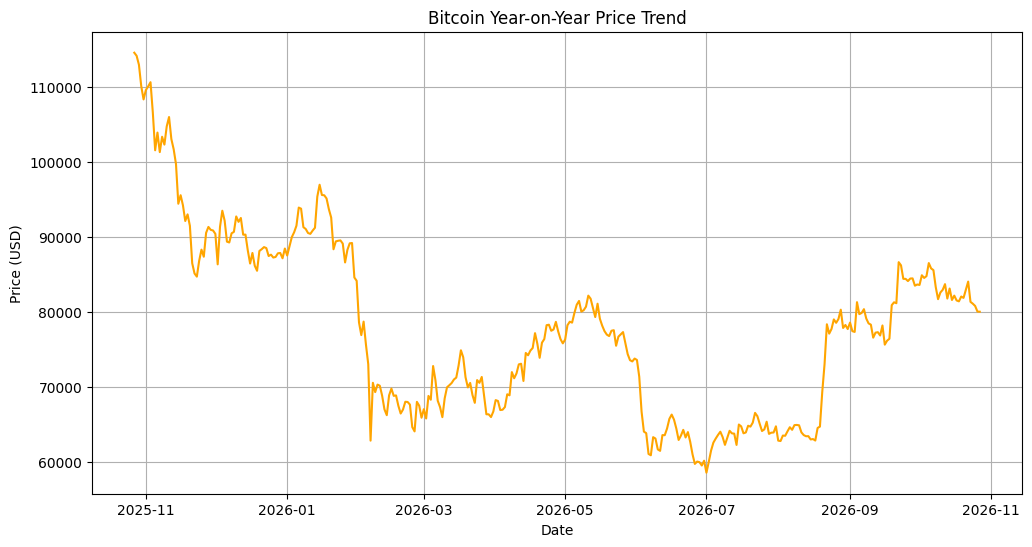

In [6]:
import pandas as pd
import matplotlib.pyplot as plt


url = 'https://api.blockchain.info/charts/market-price?format=csv'


df_bitcoin = pd.read_csv(
    url,
    names=['Date', 'Price'],
    parse_dates=['Date'],
    index_col='Date'
)

display(df_bitcoin.head())


plt.figure(figsize=(12, 6))
plt.plot(df_bitcoin.index, df_bitcoin['Price'], color='orange')

plt.title('Bitcoin Year-on-Year Price Trend')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.grid(True)

plt.show()

## Exercise 4.1

Answer the following questions regarding the `df_gdp` you created in Exercise 2.1:
  1. What are the dimensions of the DataFrame?
  2. How many valid GDP values are there?
  3. What is the average life expectancy for all countries?
  4. Sort the dataframe by Country and assign it to a new DataFrame
  5. What are the top 5 countries with the highest GDP?
  6. What are the top 5 countries with smallest population?

In [7]:
rows, columns = df_gdp.shape
print("1. Dimensions:", (rows, columns))

gdp_count = df_gdp['GDP'].notna().sum()
print("2. Valid GDP values:", gdp_count)

average_life = df_gdp['Life_Exp'].mean()
print("3. Average Life Expectancy:", average_life)

print("4. Sorted DataFrame by Country assigned to df_gdp_sorted.")
df_gdp_sorted = df_gdp.sort_values(by='Country')
display(df_gdp_sorted)

print("\n5. Top 5 countries with highest GDP:")
highest_gdp = df_gdp.sort_values(
    by='GDP', ascending=False
).head(5)
display(highest_gdp[['Country', 'GDP']])


print("\n6. Top 5 countries with smallest population:")
smallest_population = df_gdp.sort_values(
    by='Population', ascending=True
).head(5)
display(smallest_population[['Country', 'Population']])


1. Dimensions: (217, 5)
2. Valid GDP values: 199
3. Average Life Expectancy: 73.10801989434641
4. Sorted DataFrame by Country assigned to df_gdp_sorted.


,Country,Life_Exp,GDP,Population,Inc_Class
0,Afghanistan,65.617000,2122.995815,NaN,NaN
1,Albania,78.769000,19444.706898,NaN,NaN
2,Algeria,76.129000,15836.094437,NaN,NaN
3,American Samoa,72.752000,NaN,NaN,NaN
4,Andorra,84.016000,68470.075948,NaN,NaN
...,...,...,...,...,...
212,Virgin Islands (U.S.),80.319512,49793.032440,NaN,NaN
213,West Bank and Gaza,76.662000,6163.248978,NaN,NaN
214,"Yemen, Rep.",67.952000,NaN,NaN,NaN
215,Zambia,65.279000,3840.724505,NaN,NaN



5. Top 5 countries with highest GDP:


,Country,GDP
116,Luxembourg,143381.897534
171,Singapore,143094.949897
93,Ireland,136104.445332
147,Norway,123150.172908
159,Qatar,122920.498759



6. Top 5 countries with smallest population:


,Country,Population
0,Afghanistan,NaN
1,Albania,NaN
2,Algeria,NaN
3,American Samoa,NaN
4,Andorra,NaN
